Extracted (df1): 3,371 rows x 20 columns
Cleaned   (df2): 2,796 rows x 10 columns

Extracted Q/S summary (keV):
              count    mean     std      min     25%     50%      75%      max
Q_alpha_keV  2669.0 -1201.8  7373.1 -98404.0 -6172.0  -855.0   4599.0  56298.0
Q_beta_keV   2448.0   496.3  7475.6 -24190.0 -4277.4    85.2   4999.2  29530.0
S_n_keV      2668.0  7545.1  3636.4 -10026.0  5297.4  7043.2   9277.7  23970.0
S_p_keV      2655.0  7244.7  5397.4 -14690.0  3310.0  6470.0  10287.0  28540.0

Cleaned Q/S summary (keV):
              count    mean     std      min     25%     50%      75%      max
Q_alpha_keV  2181.0  -681.2  7542.2 -98404.0 -5845.0  -285.0   5465.3  56298.0
Q_beta_keV   1970.0   278.6  7346.9 -24190.0 -4686.8   551.4   5101.2  28440.0
S_n_keV      2172.0  7600.9  3626.2 -10026.0  5378.0  6955.0   9212.5  23970.0
S_p_keV      2166.0  6756.5  5319.1 -14690.0  2953.0  5571.5  10005.2  28540.0


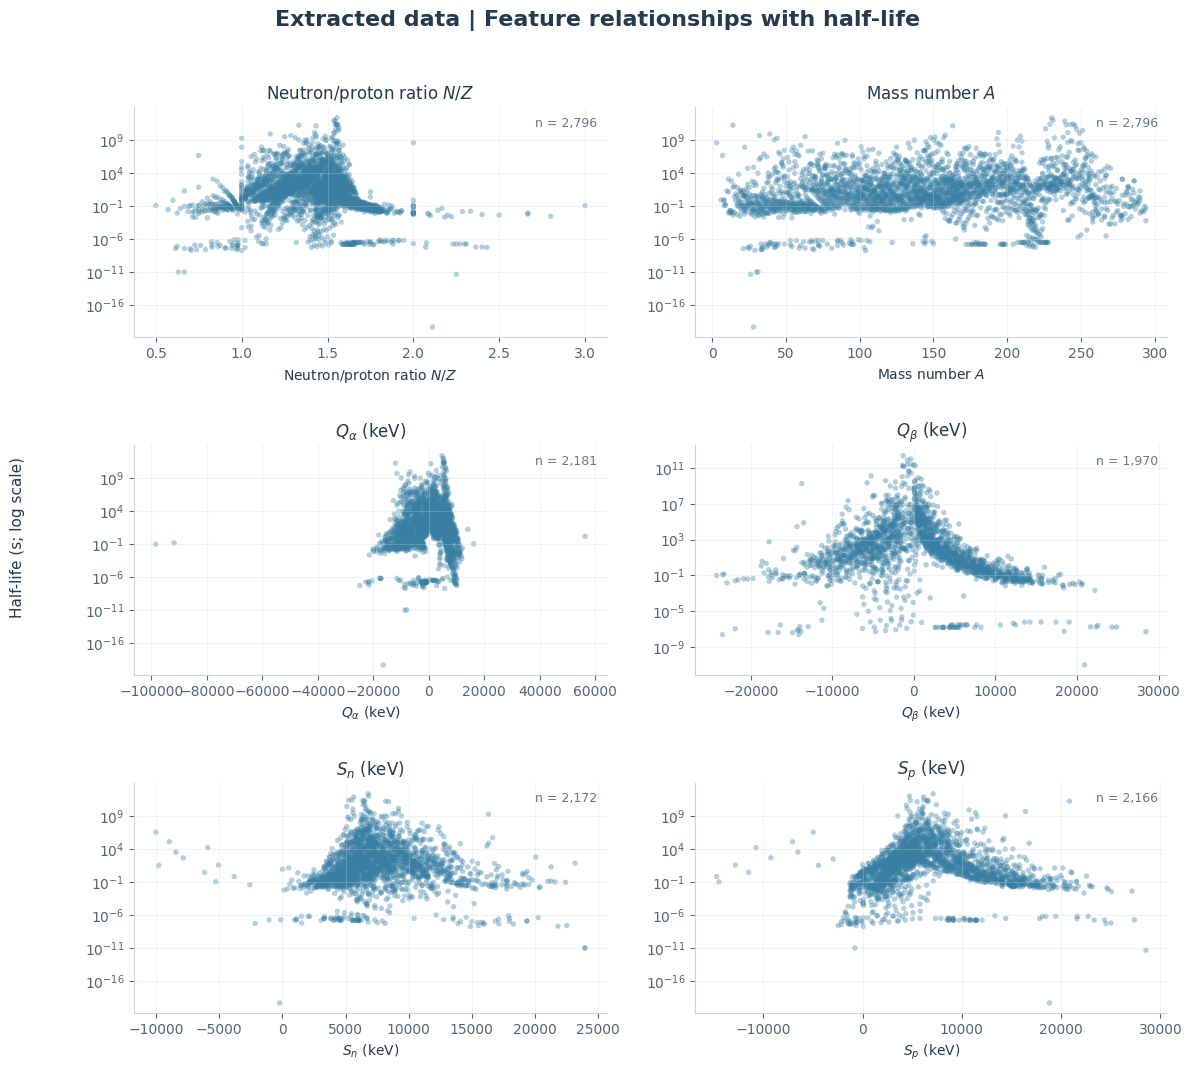

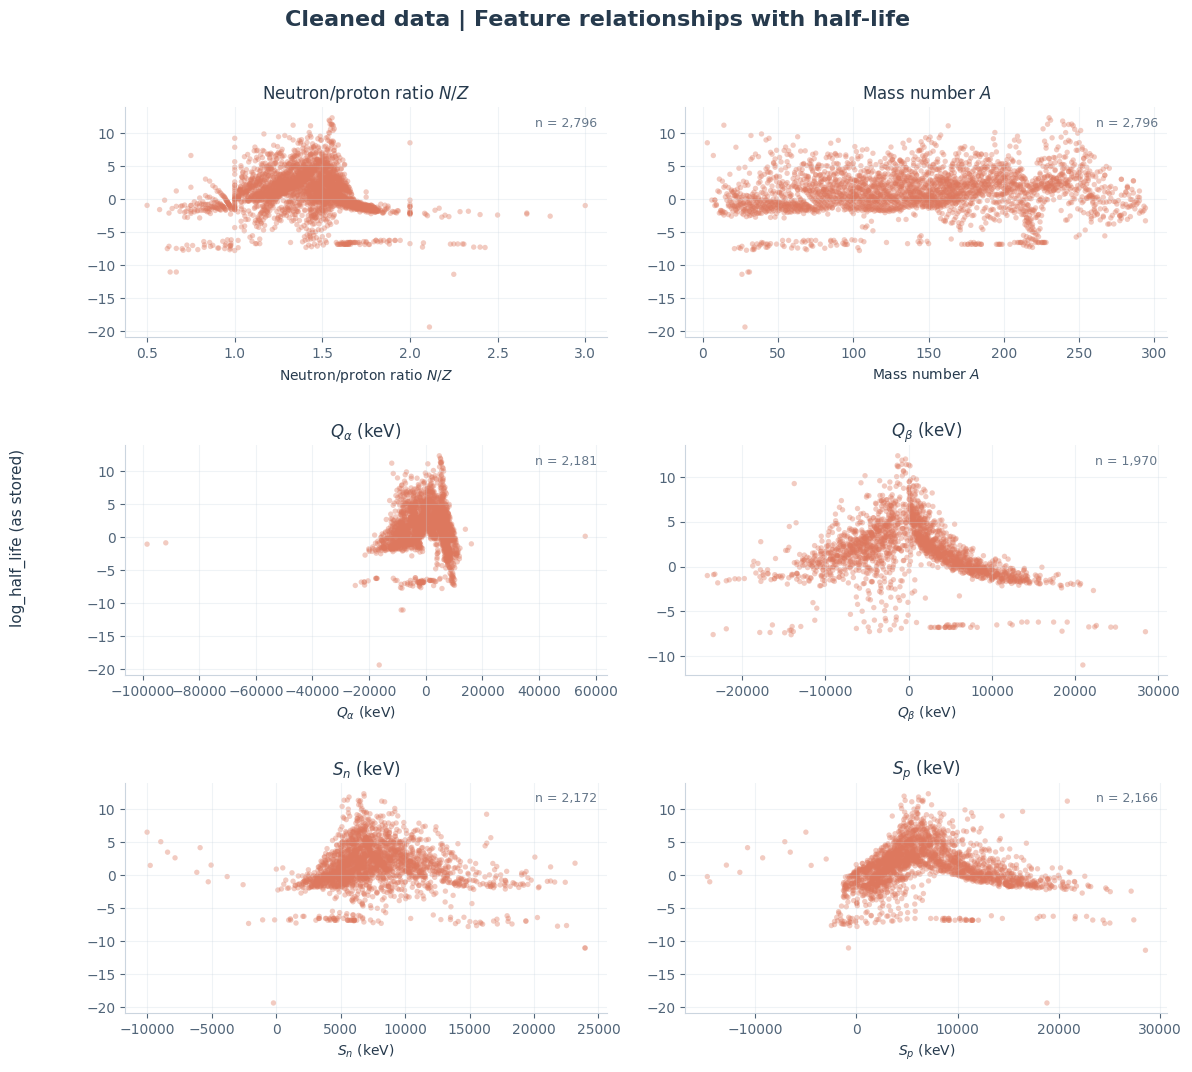

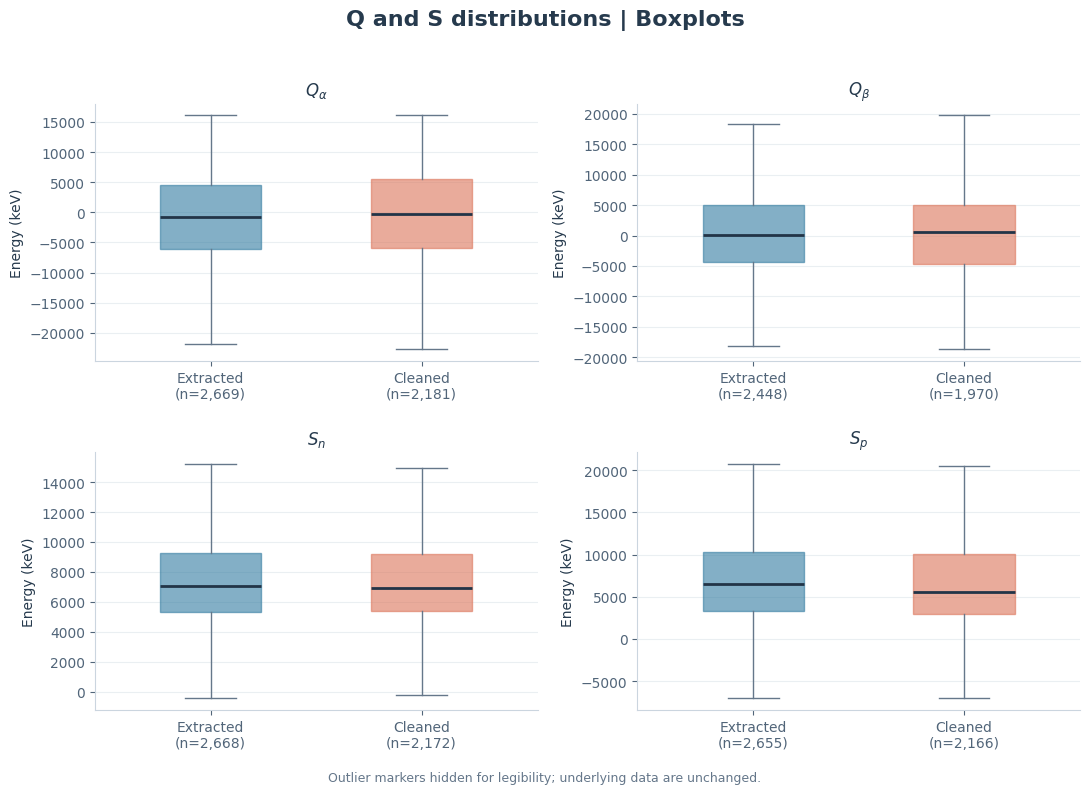

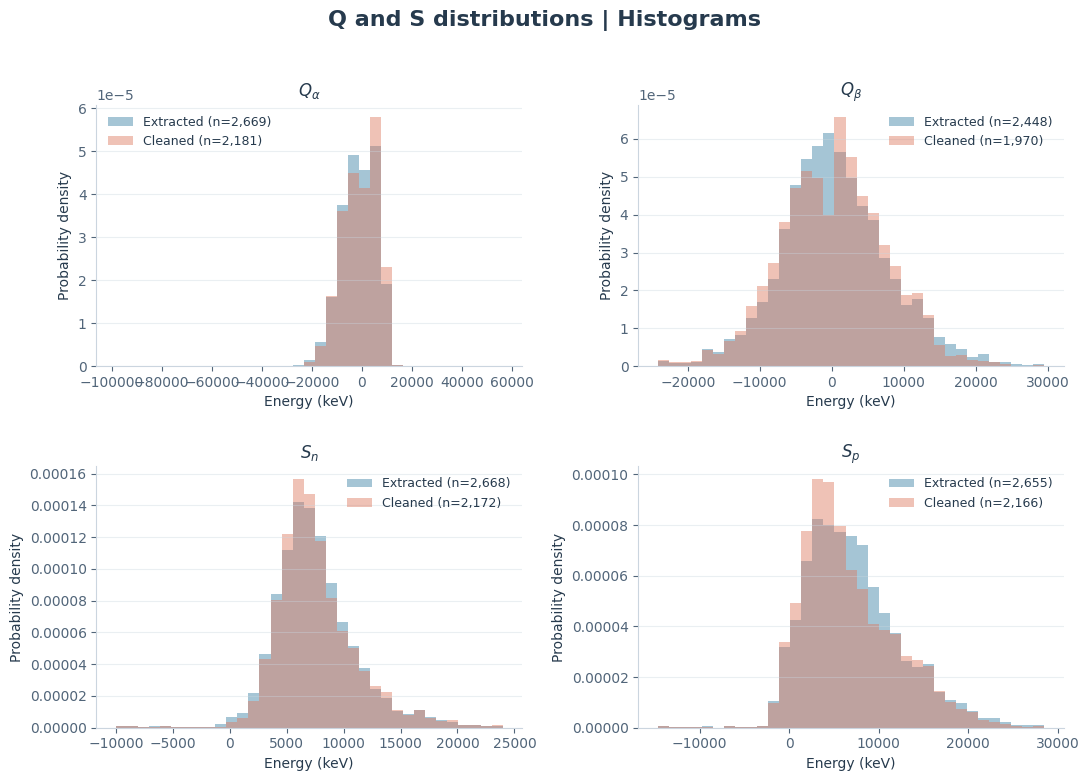

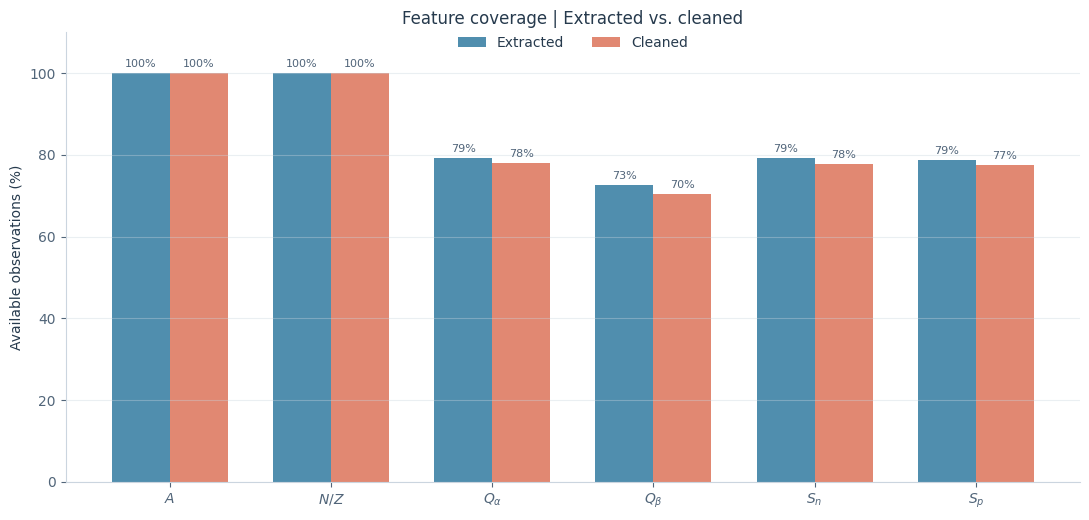


Extracted half-life status:
 half_life_status
finite          2796
stable           243
missing          215
unknown_unit     115
review             2


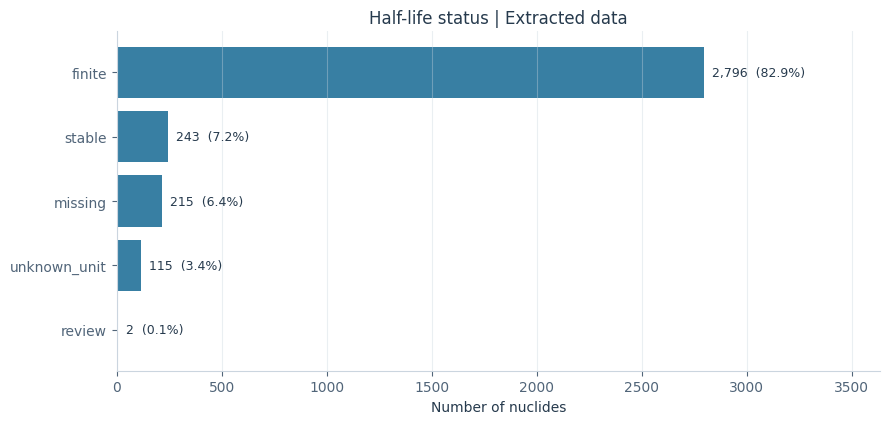

In [6]:
"""
Comparison EDA for extracted and cleaned ENSDF-derived nuclear data.

Outputs: figures saved to EDA/figures/ and displayed on screen.
The extracted half-life is plotted in seconds on a logarithmic y-axis;
cleaned log_half_life is plotted as stored (its log base is not assumed).
"""

# Imports and settings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Resolve paths whether the notebook is run from the project root or the EDA folder.
CWD = Path.cwd()

if (CWD / "EDA").is_dir():
    PROJECT_DIR = CWD
    EDA_DIR = PROJECT_DIR / "EDA"
elif CWD.name == "EDA":
    EDA_DIR = CWD
    PROJECT_DIR = CWD.parent
else:
    PROJECT_DIR = CWD
    EDA_DIR = PROJECT_DIR / "EDA"

EXTRACTED_CSV = PROJECT_DIR / "Extraction" / "extracted_data.csv"
CLEANED_CSV = EDA_DIR / "cleaned_data.csv"
FIGURE_DIR = EDA_DIR / "figures"
SAVE_FIGURES = True
SHOW_PLOTS = True

COLORS = {"Extracted": "#387FA3", "Cleaned": "#DD785E"}
ENERGY_FEATURES = {
    "Q_alpha_keV": r"$Q_{\alpha}$",
    "Q_beta_keV": r"$Q_{\beta}$",
    "S_n_keV": r"$S_n$",
    "S_p_keV": r"$S_p$",
}
SCATTER_FEATURES = {
    "N/Z": r"Neutron/proton ratio $N/Z$",
    "A": r"Mass number $A$",
    **{feature: f"{label} (keV)" for feature, label in ENERGY_FEATURES.items()},
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#CBD5DF",
    "axes.labelcolor": "#263A4D",
    "text.color": "#263A4D",
    "xtick.color": "#516579",
    "ytick.color": "#516579",
    "grid.color": "#C9D5DF",
    "grid.alpha": 0.38,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})


def load_data(path, target):
    """Load a dataset and prepare numeric columns without deleting rows."""
    if not path.is_file():
        raise FileNotFoundError(f"CSV not found: {path}")
    df = pd.read_csv(path, low_memory=False)
    required = {"A", "Z", target, *ENERGY_FEATURES}
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"{path.name} is missing columns: {sorted(missing)}")

    numeric = ["A", "Z", "N", target, *ENERGY_FEATURES]
    for col in numeric:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    if "N" not in df.columns:
        df["N"] = df["A"] - df["Z"]
    return df


def numeric_values(df, feature):
    """Finite values for one feature, excluding only missing/invalid entries."""
    values = df[feature].to_numpy(dtype=float)
    return values[np.isfinite(values)]


def finish_plot(fig, filename):
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / filename, dpi=250, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


# %% Scatter plots: N/Z, A, Q-alpha, Q-beta, S-n, S-p

def plot_scatter_grid(df, label, target):
    fig, axes = plt.subplots(3, 2, figsize=(12, 11))
    y = df[target]

    for ax, (feature, xlabel) in zip(axes.flat, SCATTER_FEATURES.items()):
        x = df["N"] / df["Z"].where(df["Z"] > 0) if feature == "N/Z" else df[feature]
        valid = np.isfinite(x) & np.isfinite(y)
        if target == "half_life_seconds":
            valid &= y > 0  # Logarithmic axes cannot show zero/negative half-lives.

        ax.scatter(x[valid], y[valid], s=15, alpha=0.38,
                   color=COLORS[label], edgecolors="none", rasterized=True)
        if target == "half_life_seconds":
            ax.set_yscale("log")
        ax.set(xlabel=xlabel, title=xlabel)
        ax.text(0.98, 0.96, f"n = {valid.sum():,}", transform=ax.transAxes,
                ha="right", va="top", fontsize=9, color="#65778A")
        ax.grid(alpha=0.28)

    y_label = ("Half-life (s; log scale)" if target == "half_life_seconds"
               else "log_half_life (as stored)")
    fig.suptitle(f"{label} data | Feature relationships with half-life",
                 fontsize=16, fontweight="bold")
    fig.supylabel(y_label, x=0.01, fontsize=11)
    fig.tight_layout(rect=(0.035, 0.01, 1, 0.96), h_pad=2.5, w_pad=1.8)
    finish_plot(fig, f"scatter_{label.lower()}.png")


# %% Comparative boxplots and histograms: Q and S only

def plot_boxplots(df1, df2):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (feature, title) in zip(axes.flat, ENERGY_FEATURES.items()):
        groups = [numeric_values(df1, feature), numeric_values(df2, feature)]
        available = [(i, values) for i, values in enumerate(groups, 1) if len(values)]
        if available:
            bp = ax.boxplot([values for _, values in available],
                            positions=[i for i, _ in available], widths=0.48,
                            patch_artist=True, showfliers=False,
                            medianprops={"color": "#223447", "linewidth": 2},
                            whiskerprops={"color": "#65778A"},
                            capprops={"color": "#65778A"})
            for patch, (i, _) in zip(bp["boxes"], available):
                color = list(COLORS.values())[i - 1]
                patch.set(facecolor=color, edgecolor=color, alpha=0.62)
        else:
            ax.text(0.5, 0.5, "No valid data", transform=ax.transAxes,
                    ha="center", va="center")
        ax.set_xticks([1, 2], [f"Extracted\n(n={len(groups[0]):,})",
                               f"Cleaned\n(n={len(groups[1]):,})"])
        ax.set(xlim=(0.45, 2.55), title=title, ylabel="Energy (keV)")
        ax.grid(axis="y")

    fig.suptitle("Q and S distributions | Boxplots", fontsize=16, fontweight="bold")
    fig.text(0.5, 0.015, "Outlier markers hidden for legibility; underlying data are unchanged.",
             ha="center", fontsize=9, color="#65778A")
    fig.tight_layout(rect=(0, 0.035, 1, 0.955), h_pad=2)
    finish_plot(fig, "boxplots_Q_S.png")


def plot_histograms(df1, df2):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (feature, title) in zip(axes.flat, ENERGY_FEATURES.items()):
        groups = [("Extracted", numeric_values(df1, feature)),
                  ("Cleaned", numeric_values(df2, feature))]
        available = [values for _, values in groups if len(values)]
        if available:
            # Shared bin edges and density scaling make sample sizes comparable.
            bins = np.histogram_bin_edges(np.concatenate(available), bins=35)
            for label, values in groups:
                if len(values):
                    ax.hist(values, bins=bins, density=True, alpha=0.45,
                            color=COLORS[label], label=f"{label} (n={len(values):,})")
            ax.legend(frameon=False, fontsize=9)
        else:
            ax.text(0.5, 0.5, "No valid data", transform=ax.transAxes,
                    ha="center", va="center")
        ax.set(xlabel="Energy (keV)", ylabel="Probability density", title=title)
        ax.grid(axis="y")

    fig.suptitle("Q and S distributions | Histograms", fontsize=16, fontweight="bold")
    fig.tight_layout(rect=(0, 0.01, 1, 0.955), h_pad=2.4)
    finish_plot(fig, "histograms_Q_S.png")


# %% Side-by-side comparison in one feature-coverage plot

def plot_coverage(df1, df2):
    columns = [
        ("A", r"$A$"),
        ("N/Z", r"$N/Z$"),
        *[(feature, label) for feature, label in ENERGY_FEATURES.items()],
    ]

    def coverage(df, feature):
        if feature == "N/Z":
            values = df["N"] / df["Z"].where(df["Z"] > 0)
        else:
            values = df[feature]

        return 100 * np.isfinite(values).mean()

    coverage1 = [coverage(df1, feature) for feature, _ in columns]
    coverage2 = [coverage(df2, feature) for feature, _ in columns]

    x = np.arange(len(columns))
    width = 0.36

    fig, ax = plt.subplots(figsize=(11, 5.3))

    for offset, label, values in [
        (-width / 2, "Extracted", coverage1),
        (width / 2, "Cleaned", coverage2)
    ]:
        bars = ax.bar(
            x + offset,
            values,
            width,
            color=COLORS[label],
            label=label,
            alpha=0.88
        )

        ax.bar_label(
            bars,
            labels=[f"{v:.0f}%" for v in values],
            padding=3,
            fontsize=8,
            color="#506479"
        )

    ax.set_xticks(x, [label for _, label in columns])
    ax.set(
        ylim=(0, 110),
        ylabel="Available observations (%)",
        title="Feature coverage | Extracted vs. cleaned"
    )
    ax.set_yticks(np.arange(0, 101, 20))
    ax.grid(axis="y")
    ax.legend(
        frameon=False,
        ncol=2,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.02)
    )

    fig.tight_layout()
    finish_plot(fig, "feature_coverage.png")


# %% Half-life status from the extracted data

def plot_half_life_status(df1):
    if "half_life_status" not in df1.columns:
        print("Half-life status unavailable: extracted data has no 'half_life_status' column.")
        return

    status = (df1["half_life_status"].astype("string").str.strip()
              .fillna("Missing").replace("", "Missing").value_counts())
    print("\nExtracted half-life status:\n", status.to_string())
    fig, ax = plt.subplots(figsize=(9, max(3.6, 0.55 * len(status) + 1.6)))
    bars = ax.barh(status.index[::-1], status.values[::-1], color=COLORS["Extracted"])
    for bar, count in zip(bars, status.values[::-1]):
        ax.text(bar.get_width() + max(len(df1) * 0.012, 0.2),
                bar.get_y() + bar.get_height() / 2,
                f"{count:,}  ({count / len(df1):.1%})", va="center", fontsize=9)
    ax.set(xlabel="Number of nuclides", title="Half-life status | Extracted data",
           xlim=(0, max(status.values) * 1.30 if len(status) else 1))
    ax.grid(axis="x")
    fig.tight_layout()
    finish_plot(fig, "half_life_status.png")


# %% Run analysis

def main():
    df1 = load_data(EXTRACTED_CSV, "half_life_seconds")
    df2 = load_data(CLEANED_CSV, "log_half_life")
    print(f"Extracted (df1): {len(df1):,} rows x {df1.shape[1]} columns")
    print(f"Cleaned   (df2): {len(df2):,} rows x {df2.shape[1]} columns")
    for label, df in [("Extracted", df1), ("Cleaned", df2)]:
        print(f"\n{label} Q/S summary (keV):")
        print(df[list(ENERGY_FEATURES)].describe().round(1).T.to_string())

    plot_scatter_grid(df1, "Extracted", "half_life_seconds")
    plot_scatter_grid(df2, "Cleaned", "log_half_life")
    plot_boxplots(df1, df2)
    plot_histograms(df1, df2)
    plot_coverage(df1, df2)
    plot_half_life_status(df1)


if __name__ == "__main__":
    main()
